# Gas Turbine CO Emission Prediction

A gas turbine in Turkey was monitored for a year: 9 process sensors (temperatures, pressures, fuel flow) plus the resulting emissions. Predict the **carbon monoxide (CO) concentration** from the process sensors — the idea behind predictive emission monitoring, which replaces expensive physical gas analysers with software.


In [1]:
import io, urllib.request, zipfile, gzip
import numpy as np
import pandas as pd

def download(url):
    req = urllib.request.Request(url, headers={'User-Agent': 'Mozilla/5.0'})
    with urllib.request.urlopen(req, timeout=180) as r:
        return r.read()
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import r2_score, mean_absolute_error

raw = download('https://archive.ics.uci.edu/static/public/551/gas+turbine+co+and+nox+emission+data+set.zip')
zf = zipfile.ZipFile(io.BytesIO(raw))
frames = [pd.read_csv(io.BytesIO(zf.read(n))) for n in zf.namelist() if n.endswith('.csv')]
df = pd.concat(frames, ignore_index=True)
print(df.shape)
df.head()

(36733, 11)


,AT,AP,AH,AFDP,GTEP,TIT,TAT,TEY,CDP,CO,NOX
0,4.5878,1018.7,83.675,3.5758,23.979,1086.2,549.83,134.67,11.898,0.32663,81.952
1,4.2932,1018.3,84.235,3.5709,23.951,1086.1,550.05,134.67,11.892,0.44784,82.377
2,3.9045,1018.4,84.858,3.5828,23.990,1086.5,550.19,135.10,12.042,0.45144,83.776
3,3.7436,1018.3,85.434,3.5808,23.911,1086.5,550.17,135.03,11.990,0.23107,82.505
4,3.7516,1017.8,85.182,3.5781,23.917,1085.9,550.00,134.67,11.910,0.26747,82.028


In [2]:
X = df.drop(columns=['CO', 'NOX']); y = df['CO']
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.25, random_state=42)
rf = RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1).fit(Xtr, ytr)
lin = make_pipeline(StandardScaler(), LinearRegression()).fit(Xtr, ytr)
for name_m, m in [('Random Forest', rf), ('Linear', lin)]:
    p = m.predict(Xte)
    print(f'{name_m:15s} R2 {r2_score(yte, p):.3f}  MAE {mean_absolute_error(yte, p):.3f} mg/m3')

Random Forest   R2 0.777  MAE 0.484 mg/m3
Linear          R2 0.567  MAE 0.852 mg/m3


TIT     0.513879
TAT     0.199331
AFDP    0.058959
AT      0.046410
AH      0.040831
GTEP    0.040131
TEY     0.039950
AP      0.034886
CDP     0.025623
dtype: float64


<Axes: title={'center': 'Which sensors predict CO emissions?'}>

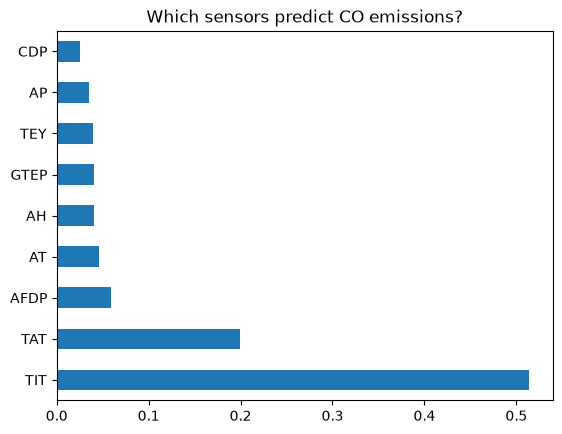

In [3]:
imp = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False)
print(imp)
imp.plot(kind='barh', title='Which sensors predict CO emissions?')